# Distribución de Weibull
La distribución de Weibull es muy utilizada en ingeniería de fiabilidad, análisis de vida útil y mantenimiento predictivo. Permite modelar tiempos hasta el fallo de componentes.

## Parámetros principales
- **β (beta, parámetro de forma)**
  - β < 1: tasa de fallo decreciente.
  - β = 1: comportamiento exponencial.
  - β > 1: tasa de fallo creciente (desgaste).

- **η (eta, parámetro de escala)**
  - Controla la dispersión y la posición de la distribución.

## Función de densidad de probabilidad (PDF)
$f(t)=\frac{\beta}{\eta}\left(\frac{t}{\eta}\right)^{\beta-1}e^{-\left(\frac{t}{\eta}\right)^{\beta}}$

## Función de fiabilidad
$R(t)=e^{-\left(\frac{t}{\eta}\right)^{\beta}}$

## Probabilidad acumulada de fallo
$F(t)=1-e^{-\left(\frac{t}{\eta}\right)^{\beta}}$

Utiliza los sliders para modificar β y η y observar cómo cambia la PDF.

## B10
tiempo (o ciclos, km, horas, etc.) al que se espera que haya fallado el 10% de la población.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from ipywidgets import interact

def weibull_pdf(t, beta, eta):
    return (beta/eta) * (t/eta)**(beta-1) * np.exp(-(t/eta)**beta)

def plot_weibull(beta=2.0, eta=100.0):
    t = np.linspace(0.001, eta*3, 1000)
    pdf = weibull_pdf(t, beta, eta)

    plt.figure(figsize=(10,5))
    plt.plot(t, pdf, linewidth=2, label=f"β={beta:.2f}, η={eta:.1f}")
    plt.title("Distribución de Weibull (PDF)")
    plt.xlabel("Tiempo")
    plt.ylabel("Densidad de probabilidad")
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.show()

interact(
    plot_weibull,
    beta=widgets.FloatSlider(value=2.0,min=0.2,max=10.0,step=0.1,description="β Forma"),
    eta=widgets.FloatSlider(value=100.0,min=10,max=1000,step=10,description="η Escala")
);


interactive(children=(FloatSlider(value=2.0, description='β Forma', max=10.0, min=0.2), FloatSlider(value=100.…

In [28]:
import pandas as pd

archivo = "Failure_values.xlsx"

df = pd.read_excel(archivo)

values = df["Values"].dropna()

print(f"Número de muestras: {len(values)}")

Número de muestras: 6


In [29]:
values

0    6259
1    6306
2    6285
3    6263
4    6275
5    6196
Name: Values, dtype: int64

In [37]:
from scipy.stats import weibull_min

beta, loc, eta = weibull_min.fit(values, floc=0)

B10 = eta * (-np.log(0.9))**(1/beta)


print("Parámetro de forma β =", round(beta,3))
print("Parámetro de escala η =", round(eta,3))
print("B10 =", round(B10,3))

Parámetro de forma β = 248.063
Parámetro de escala η = 6279.174
B10 = 6222.468


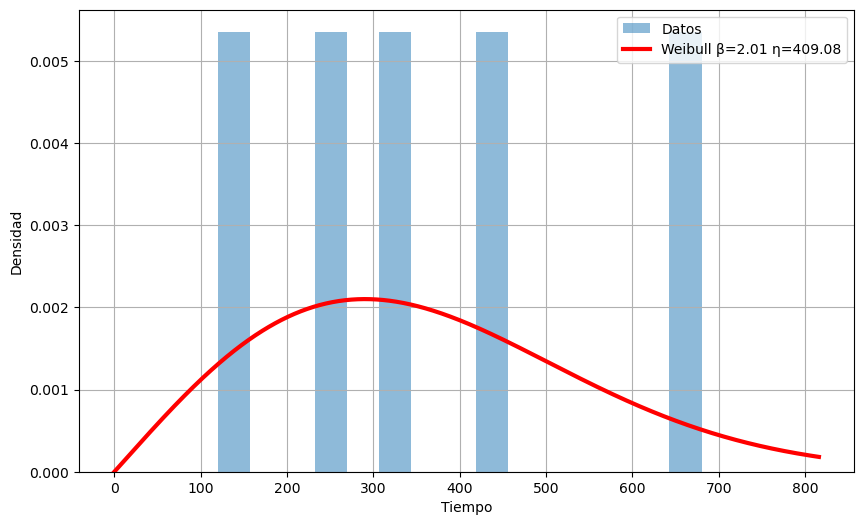

In [12]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import weibull_min

x = np.linspace(0, values.max()*1.2, 1000)

pdf = weibull_min.pdf(
    x,
    beta,
    loc=0,
    scale=eta
)

plt.figure(figsize=(10,6))

plt.hist(
    tiempos,
    bins=15,
    density=True,
    alpha=0.5,
    label="Datos"
)

plt.plot(
    x,
    pdf,
    'r',
    lw=3,
    label=f"Weibull β={beta:.2f} η={eta:.2f}"
)

plt.xlabel("Tiempo")
plt.ylabel("Densidad")
plt.grid(True)
plt.legend()

plt.show()